# Exploratory Data Analysis (EDA)

Di Note ini

1. Apakah produk yang lebih mahal mendapat rating lebih tinggi?
2. Kategori skincare mana yang paling sering membuat pelanggan kecewa?
3. Apakah kepuasan berbeda menurut jenis kulit?
4. Bagaimana tren jumlah ulasan dan rating dari tahun ke tahun?
5. Bagaimana performa brand-brand terbesar?

**Definisi metrik yang dipakai:**
- **Rating rata-rata**: rata-rata bintang (1–5) dari ulasan
- **% ulasan negatif**: persentase ulasan dengan rating 1–2 (ukuran *ketidakpuasan*)
- **% merekomendasikan**: persentase pengulas yang menjawab "ya, saya rekomendasikan"

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

products = pd.read_parquet(PROCESSED / "products_skincare.parquet")
reviews = pd.read_parquet(PROCESSED / "reviews_clean.parquet")
print(f"Produk: {len(products):,} | Ulasan: {len(reviews):,}")

Produk: 2,420 | Ulasan: 1,092,967


In [2]:
# Palet warna: satu warna utama (biru) + abu-abu untuk konteks.
# Warna dipakai untuk MENYOROTI temuan, bukan dekorasi.
BLUE = "#2a78d6"      # warna utama / sorotan
GREY = "#c9c8c1"      # data pembanding
TEXT = "#0b0b0b"
TEXT_2 = "#52514e"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#d6d5ce", "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae4", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print("Disimpan:", FIG_DIR / f"{name}.png")

def neg_rate(s):
    return (s <= 2).mean()

## Apakah produk lebih mahal = rating lebih tinggi?
Kita bandingkan 4 kelompok harga dari Langkah 1: `< $25`, `$25-50`, `$50-100`, `> $100`.

In [3]:
price_tbl = reviews.groupby("price_band", observed=True).agg(
    jumlah_ulasan=("rating", "size"),
    rating_rata2=("rating", "mean"),
    pct_rekomendasi=("is_recommended", "mean"),
)
price_tbl["jumlah_produk"] = products.groupby("price_band", observed=True).size()
price_tbl = price_tbl[["jumlah_produk", "jumlah_ulasan", "rating_rata2", "pct_rekomendasi"]]
price_tbl

,jumlah_produk,jumlah_ulasan,rating_rata2,pct_rekomendasi
price_band,,,,
< $25,485,268139,4.260026,0.816044
$25-50,921,428887,4.301359,0.839637
$50-100,746,331010,4.333437,0.858792
> $100,268,64931,4.271380,0.839220


In [4]:
corr = products[["price_usd", "rating"]].corr(method="spearman").iloc[0, 1]
print(f"Korelasi Spearman harga vs rating produk: {corr:.2f}")

Korelasi Spearman harga vs rating produk: 0.13


Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\01_price_band.png


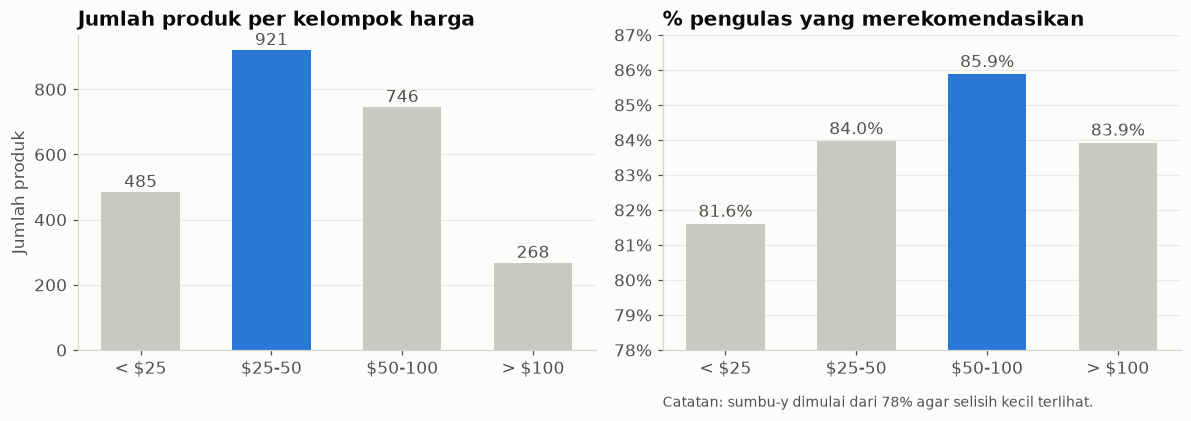

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bands = price_tbl.index.astype(str)

# Kiri: jumlah produk (di mana kompetisinya?)
ax = axes[0]
colors = [BLUE if b == "$25-50" else GREY for b in bands]
ax.bar(bands, price_tbl["jumlah_produk"], color=colors, width=0.6)
for i, v in enumerate(price_tbl["jumlah_produk"]):
    ax.text(i, v + 15, f"{v:,}", ha="center", color=TEXT_2)
ax.set_title("Jumlah produk per kelompok harga")
ax.set_ylabel("Jumlah produk"); ax.grid(axis="x", visible=False)

# Kanan: % merekomendasikan
ax = axes[1]
vals = price_tbl["pct_rekomendasi"]
colors = [BLUE if b == "$50-100" else GREY for b in bands]
ax.bar(bands, vals, color=colors, width=0.6)
for i, v in enumerate(vals):
    ax.text(i, v + 0.002, f"{v:.1%}", ha="center", color=TEXT_2)
ax.set_ylim(0.78, 0.87)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("% pengulas yang merekomendasikan")
ax.grid(axis="x", visible=False)
ax.text(0, -0.18, "Catatan: sumbu-y dimulai dari 78% agar selisih kecil terlihat.",
        transform=ax.transAxes, fontsize=9, color=TEXT_2)

fig.tight_layout(); save(fig, "01_price_band"); plt.show()

**Insight:**
- Hubungan harga dan rating **sangat lemah** (korelasi Spearman ≈ 0,13). Harga mahal tidak menjamin pelanggan puas.
- Kelompok **$50-100** punya tingkat rekomendasi tertinggi (~86%), tetapi produk **> $100** justru turun lagi (~84%). Ekspektasi pelanggan yang tinggi tidak selalu terpenuhi.
- Kompetisi paling padat ada di **$25-50** (921 produk).

**Implikasi untuk brand lokal:** bersaing di harga terjangkau tetap bisa menghasilkan kepuasan tinggi, karena kualitas produk lebih menentukan daripada harga.

## Kategori mana yang paling sering mengecewakan?
Kita hitung **% ulasan negatif (rating 1–2)** per kategori. Kategori dengan ulasan < 5.000 tidak dimasukkan supaya angkanya stabil.

In [6]:
cat_tbl = reviews.groupby("secondary_category").agg(
    jumlah_ulasan=("rating", "size"),
    rating_rata2=("rating", "mean"),
    pct_negatif=("rating", neg_rate),
    pct_rekomendasi=("is_recommended", "mean"),
)
cat_tbl = cat_tbl[cat_tbl["jumlah_ulasan"] >= 5000].sort_values("pct_negatif", ascending=False)
cat_tbl

,jumlah_ulasan,rating_rata2,pct_negatif,pct_rekomendasi
secondary_category,,,,
Self Tanners,11926,4.080329,0.160238,0.789124
High Tech Tools,5920,4.176014,0.149662,0.811672
Sunscreen,41100,4.166788,0.138078,0.803597
Wellness,10515,4.172515,0.126771,0.810881
Eye Care,74919,4.178660,0.117113,0.826377
Value & Gift Sets,12089,4.268178,0.112995,0.842749
Mini Size,85397,4.285666,0.108845,0.827745
Lip Balms & Treatments,61549,4.333897,0.107069,0.810781
Treatments,221690,4.304258,0.100889,0.853498


Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\02_negative_by_category.png


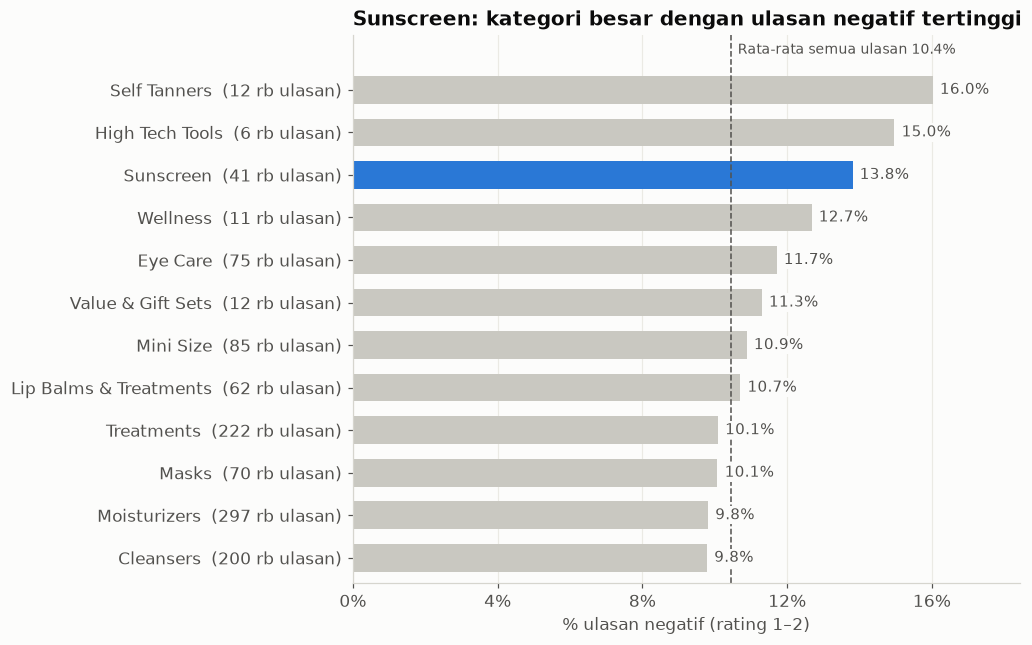

In [7]:
plot_df = cat_tbl.sort_values("pct_negatif")
overall = neg_rate(reviews["rating"])
# Sorot Sunscreen: kategori BESAR (>40 rb ulasan) dengan % negatif tertinggi
colors = [BLUE if c == "Sunscreen" else GREY for c in plot_df.index]
labels = [f"{c}  ({n/1000:.0f} rb ulasan)" for c, n in zip(plot_df.index, plot_df["jumlah_ulasan"])]

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(labels, plot_df["pct_negatif"], color=colors, height=0.65)
for i, v in enumerate(plot_df["pct_negatif"]):
    ax.text(v + 0.002, i, f"{v:.1%}", va="center", color=TEXT_2, fontsize=10,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(overall, color=TEXT_2, linestyle="--", linewidth=1)
ax.set_ylim(-0.6, len(plot_df) + 0.3)
ax.text(overall + 0.002, len(plot_df) - 0.15, f"Rata-rata semua ulasan {overall:.1%}", color=TEXT_2, fontsize=9)
ax.set_xlim(0, plot_df["pct_negatif"].max() * 1.15)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% ulasan negatif (rating 1–2)")
ax.set_title("Sunscreen: kategori besar dengan ulasan negatif tertinggi")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "02_negative_by_category"); plt.show()

**Insight:**
- **Sunscreen** punya 13,8% ulasan negatif, tertinggi di antara kategori besar (41 ribu ulasan) dan jauh di atas rata-rata (~10,4%).
- **Self Tanners** (16,0%) dan **High Tech Tools** (15,0%) lebih tinggi lagi, tetapi volumenya kecil (12 rb & 6 rb ulasan).
- Kategori terbesar seperti **Moisturizers, Cleansers, Treatments** relatif aman (~10%).

**Implikasi untuk brand lokal:** sunscreen adalah kategori yang sangat relevan di pasar Indonesia, dan di sini terlihat banyak pelanggan belum puas. Ini **peluang**: produk yang menyelesaikan keluhan utama sunscreen bisa menonjol. Apa keluhannya? Kita gali di **Langkah 3** (analisis teks ulasan).

## Apakah kepuasan berbeda menurut jenis kulit?

In [8]:
skin_tbl = reviews[reviews["skin_type"] != "unknown"].groupby("skin_type").agg(
    jumlah_ulasan=("rating", "size"),
    rating_rata2=("rating", "mean"),
    pct_negatif=("rating", neg_rate),
    pct_rekomendasi=("is_recommended", "mean"),
)
skin_tbl["porsi_ulasan"] = skin_tbl["jumlah_ulasan"] / skin_tbl["jumlah_ulasan"].sum()
skin_tbl.sort_values("jumlah_ulasan", ascending=False)

,jumlah_ulasan,rating_rata2,pct_negatif,pct_rekomendasi,porsi_ulasan
skin_type,,,,,
combination,543778,4.309442,0.099607,0.844860,0.554056
dry,185675,4.291003,0.108205,0.836235,0.189185
normal,131687,4.282086,0.108067,0.834287,0.134176
oily,120309,4.270977,0.110166,0.833801,0.122583


Selisih antar-jenis kulit secara keseluruhan kecil. Pola yang lebih menarik muncul saat jenis kulit **dikombinasikan dengan kategori**. Heatmap di bawah menunjukkan % ulasan negatif. Semakin gelap warnanya, semakin banyak pelanggan yang kecewa.

Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\03_heatmap_category_skin.png


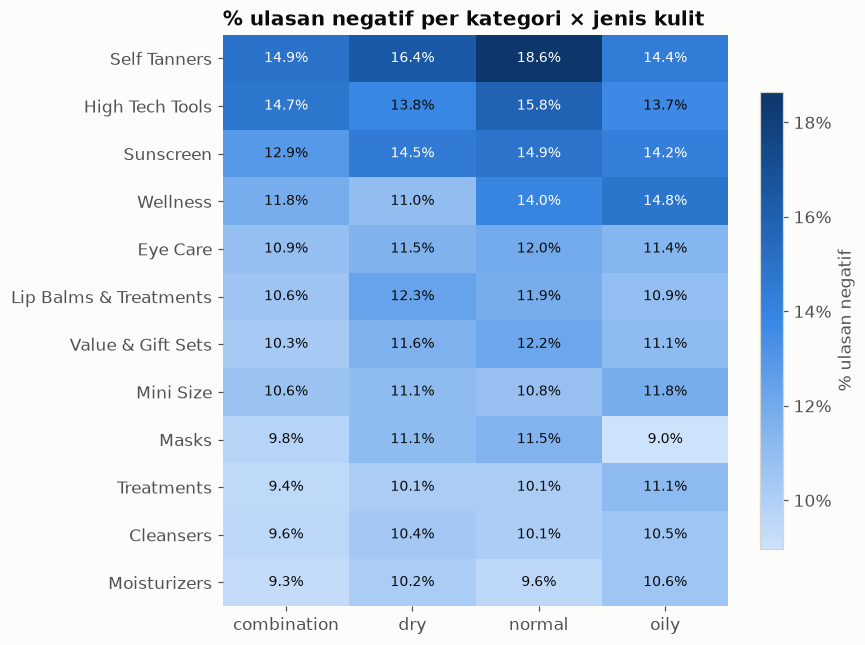

In [9]:
heat = (
    reviews[(reviews["skin_type"] != "unknown") & reviews["secondary_category"].isin(cat_tbl.index)]
    .pivot_table(index="secondary_category", columns="skin_type", values="rating", aggfunc=neg_rate)
)
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index, ["combination", "dry", "normal", "oily"]]

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(heat.values, cmap=blues, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
threshold = heat.values.min() + (heat.values.max() - heat.values.min()) * 0.5
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=9,
                color="white" if v > threshold else TEXT)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1, decimals=0), shrink=0.8)
cbar.set_label("% ulasan negatif")
ax.set_title("% ulasan negatif per kategori × jenis kulit")
fig.tight_layout(); save(fig, "03_heatmap_category_skin"); plt.show()

**Insight:**
- **Combination skin** mendominasi ulasan (~55%), sehingga ini segmen pelanggan terbesar.
- Secara keseluruhan selisih rating antar-jenis kulit **kecil** (4,27–4,31). Jenis kulit saja bukan pembeda utama.
- Kombinasi yang menonjol: **Self Tanners untuk kulit normal** (18,6%), serta **Sunscreen untuk kulit kering, normal, dan berminyak** (14–15%, dibanding 12,9% di kulit combination). Kulit **berminyak (oily)** juga sedikit lebih kecewa pada Moisturizers & Treatments.

**Implikasi:** klaim produk sebaiknya spesifik per jenis kulit, misalnya "sunscreen untuk kulit kering yang tidak bikin kering/ketarik".

## Tren ulasan dari tahun ke tahun
Data 2023 hanya sampai **Maret**, jadi jumlah ulasannya tidak bisa dibandingkan dengan tahun penuh. Tahun 2023 ditandai abu-abu.

Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\04_yearly_trend.png


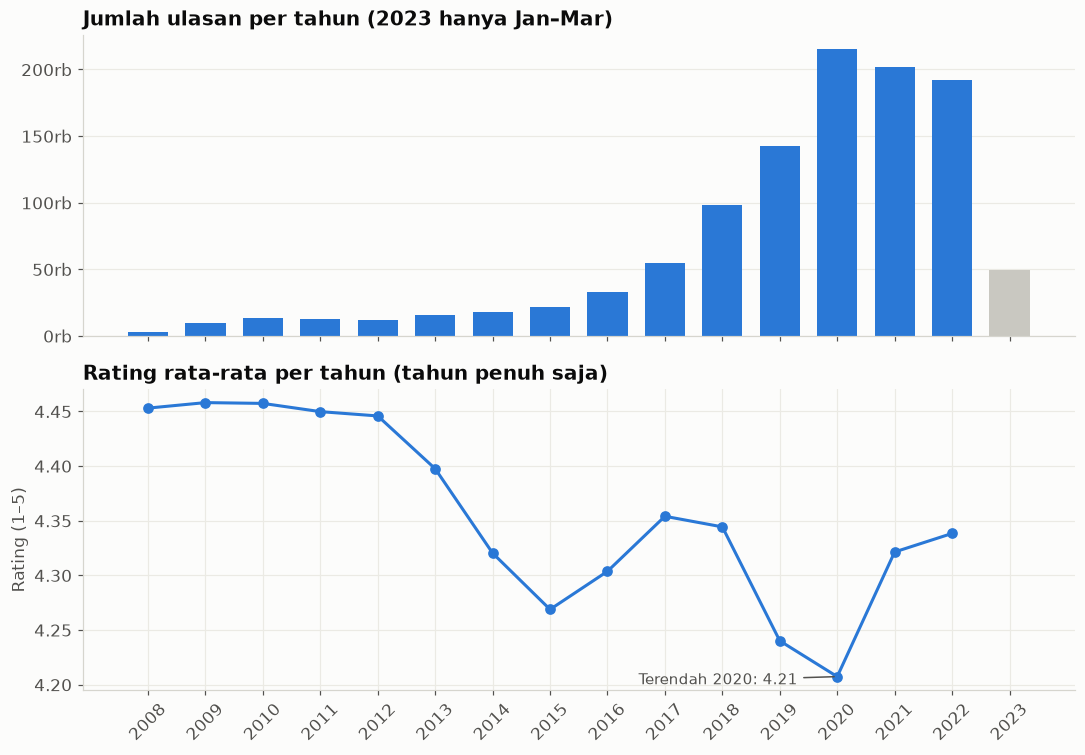

In [10]:
year_tbl = reviews.groupby("year").agg(jumlah_ulasan=("rating", "size"), rating_rata2=("rating", "mean"))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax = axes[0]
colors = [GREY if y == 2023 else BLUE for y in year_tbl.index]
ax.bar(year_tbl.index, year_tbl["jumlah_ulasan"], color=colors, width=0.7)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}rb"))
ax.set_title("Jumlah ulasan per tahun (2023 hanya Jan–Mar)")
ax.grid(axis="x", visible=False)

ax = axes[1]
full = year_tbl.loc[year_tbl.index < 2023]
ax.plot(full.index, full["rating_rata2"], color=BLUE, linewidth=2, marker="o", markersize=6)
low = full["rating_rata2"].idxmin()
ax.annotate(f"Terendah {low}: {full.loc[low, 'rating_rata2']:.2f}", (low, full.loc[low, "rating_rata2"]),
            xytext=(-130, -5), textcoords="offset points", color=TEXT_2, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=TEXT_2))
ax.set_title("Rating rata-rata per tahun (tahun penuh saja)")
ax.set_ylabel("Rating (1–5)")
ax.set_xticks(year_tbl.index)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); save(fig, "04_yearly_trend"); plt.show()

**Insight:**
- Jumlah ulasan **melonjak sejak 2017** dan mencapai puncak di **2020** (~215 ribu). Kemungkinan dipicu tren belanja online selama pandemi.
- Rating rata-rata **turun bertahap** dari ~4,45 (2008–2012) ke titik terendah **4,21 di 2020**, lalu pulih ke ~4,33 (2021–2022).
- Pola ini menunjukkan: saat pembeli baru membanjir, ekspektasi makin beragam dan rating cenderung turun.

##  Performa 10 brand dengan ulasan terbanyak

In [11]:
brand_tbl = reviews.groupby("brand_name").agg(
    jumlah_ulasan=("rating", "size"),
    rating_rata2=("rating", "mean"),
    pct_negatif=("rating", neg_rate),
    pct_rekomendasi=("is_recommended", "mean"),
).sort_values("jumlah_ulasan", ascending=False).head(10)
brand_tbl

,jumlah_ulasan,rating_rata2,pct_negatif,pct_rekomendasi
brand_name,,,,
CLINIQUE,48977,4.249974,0.106111,0.834642
Tatcha,46687,4.241052,0.122647,0.812801
Drunk Elephant,42309,4.085112,0.160651,0.766809
fresh,40828,4.376457,0.089399,0.864930
The Ordinary,35809,4.211511,0.138485,0.819152
Glow Recipe,31473,4.314937,0.106599,0.837628
Youth To The People,29119,4.281878,0.121604,0.819736
Origins,29042,4.359893,0.086805,0.866500
Peter Thomas Roth,28818,4.315983,0.106739,0.848358


Disimpan: C:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\05_top_brands.png


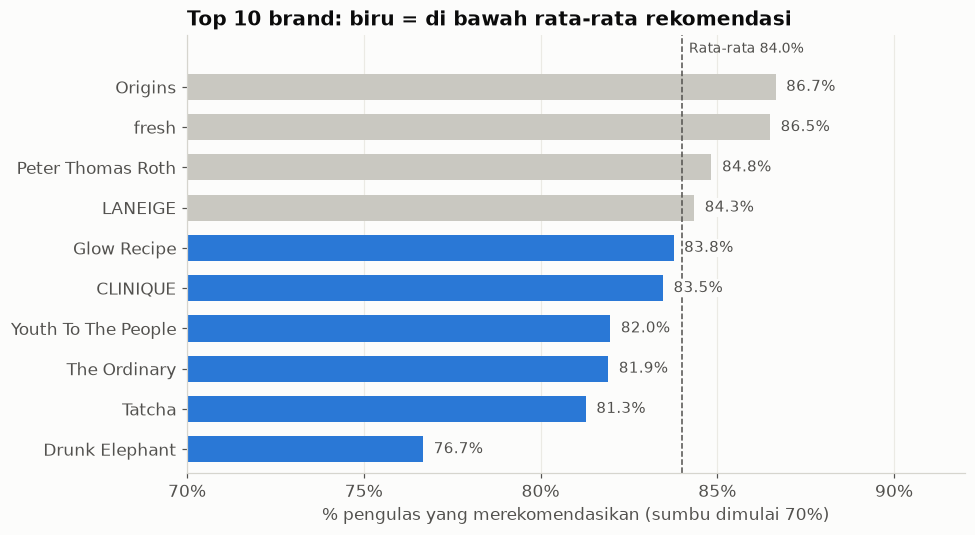

In [12]:
plot_df = brand_tbl.sort_values("pct_rekomendasi")
avg_rec = reviews["is_recommended"].mean()
colors = [BLUE if v < avg_rec else GREY for v in plot_df["pct_rekomendasi"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df.index, plot_df["pct_rekomendasi"], color=colors, height=0.65)
for i, v in enumerate(plot_df["pct_rekomendasi"]):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", color=TEXT_2, fontsize=10,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(avg_rec, color=TEXT_2, linestyle="--", linewidth=1)
ax.set_ylim(-0.6, len(plot_df) + 0.3)
ax.text(avg_rec + 0.002, len(plot_df) - 0.15, f"Rata-rata {avg_rec:.1%}", color=TEXT_2, fontsize=9)
ax.set_xlim(0.7, 0.92)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% pengulas yang merekomendasikan (sumbu dimulai 70%)")
ax.set_title("Top 10 brand: biru = di bawah rata-rata rekomendasi")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "05_top_brands"); plt.show()

**Insight:**
- Brand populer tidak otomatis paling disukai. **Drunk Elephant** punya ulasan sangat banyak, tetapi rating & rekomendasinya paling rendah di antara top 10.
- **fresh, LANEIGE, Origins** konsisten di atas rata-rata.

**Implikasi:** volume ulasan (popularitas) dan kepuasan adalah dua hal berbeda, sehingga brand perlu memantau keduanya.

## Ringkasan 

| # | Pertanyaan | Temuan utama |
|---|---|---|
| 1 | Harga vs rating | Hubungan lemah (ρ ≈ 0,13); $50-100 paling direkomendasikan, > $100 turun |
| 2 | Kategori bermasalah | **Sunscreen** (13,8%): ulasan negatif tertinggi di antara kategori besar |
| 3 | Jenis kulit | Combination = segmen terbesar; pembeda muncul di kombinasi kategori × jenis kulit |
| 4 | Tren | Ulasan melonjak 2017–2020; rating terendah di 2020, lalu pulih |
| 5 | Brand | Popularitas ≠ kepuasan (contoh: Drunk Elephant) |